# Blok 9: Python – Praca z danymi (analiza i wizualizacja)
## Ćwiczenia (CLEAN) – zadania z TODO

**Cel notatnika:** przejść cały workflow pracy z danymi: wczytanie → szybki przegląd → EDA → czyszczenie → wizualizacja → wnioski.

**Zasada:** w tym notatniku masz treści zadań + szkielety i TODO. Rozwiązania są w `cwiczenia_solved.ipynb`.


## Opis datasetu

**Nazwa zbioru:** Video Game Sales (vgsales)

**Plik:** `vgsales_clean.csv`

**Kontekst biznesowy:** analiza rynku gier wideo – które platformy/genre/publisherzy dominują, jak zmienia się sprzedaż w czasie i w regionach.

**Kolumny (nazwa → typ → opis biznesowy):**
- `Rank` → int → ranking sprzedaży globalnej (1 = największa)
- `Name` → str → tytuł gry
- `Platform` → str/category → platforma (np. Wii, NES, PS4)
- `Year` → int/float → rok wydania
- `Genre` → str/category → gatunek (np. Action, Sports)
- `Publisher` → str/category → wydawca
- `NA_Sales` → float → sprzedaż w Ameryce Płn. (mln szt.)
- `EU_Sales` → float → sprzedaż w Europie (mln szt.)
- `JP_Sales` → float → sprzedaż w Japonii (mln szt.)
- `Other_Sales` → float → sprzedaż w pozostałych regionach (mln szt.)
- `Global_Sales` → float → sprzedaż globalna (mln szt.)

**Etykiety/kategorie:** `Platform`, `Genre`, `Publisher`.

**Uwaga jakościowa:** nawet jeśli plik nazywa się „clean”, ćwiczymy nawyki: typy, braki, duplikaty, sanity checks (np. spójność sum regionów z `Global_Sales`).


## Importy i ustawienia
Uruchom tę komórkę jako pierwszą.

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# seaborn jest opcjonalny
try:
    import seaborn as sns
    _HAS_SEABORN = True
except ImportError:
    _HAS_SEABORN = False

# polars jest opcjonalny (pokażemy na końcu)
try:
    import polars as pl
    _HAS_POLARS = True
except ImportError:
    _HAS_POLARS = False

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)
pd.set_option('display.max_rows', 20)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


# Część A. NumPy (rozgrzewka, ~60 min)
Cel: poczuć tablice `ndarray`, wektoryzację, indeksowanie, statystyki i `axis`.


### Zadanie 1: NumPy – tworzenie tablic
**Cel techniczny:** `np.array`, `np.arange`, `np.zeros`, `np.ones`.

1) Utwórz tablicę 1D z liczbami 1..10.
2) Utwórz tablicę parzystych liczb od 0 do 18.
3) Utwórz macierz 3x4 wypełnioną zerami.
4) Utwórz wektor długości 5 wypełniony jedynkami.


In [12]:
a = np.arange(1, 11)
b = np.arange(0, 20, 2)
m = np.zeros((3, 4))
ones = np.ones(5)

print(a)
print(b)
print(m)
print(ones)


[ 1  2  3  4  5  6  7  8  9 10]
[ 0  2  4  6  8 10 12 14 16 18]
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
[1. 1. 1. 1. 1.]


### Zadanie 2: NumPy – operacje matematyczne i wektoryzacja
**Kontekst:** masz dwie „miary” (np. sprzedaż w 2 regionach) i chcesz policzyć sumę oraz procentową zmianę bez pętli.

1) Stwórz dwie tablice `x` i `y` (np. po 8 liczb) i policz `x + y`, `x - y`, `x * y`.
2) Policz pierwiastek z `x` (tam gdzie ma sens) i logarytm z `x + 1`.
3) Porównaj wynik obliczeń z wersją pętli (tylko 1 przykład) i zobacz różnicę w czytelności.


In [22]:
x = np.random.randint(1, 100, size=10)
y = np.random.randint(1, 100, size=10)

suma = x + y
roznica = np.max(x) - np.min(y)
iloczy = x * y
sqrt_x = np.sqrt(x)
log_x = np.log(x + 1)

print("x: ", x)
print("y: ", y)
print("suma: ", suma)
print("roznica: ", roznica)
print("iloczy: ", iloczy)
print("sqrt_x: ", sqrt_x)
print("log_x: ", log_x)

arr = []
for a, b in zip(x, y):
    arr.append(int(a) + int(b))
print("arr: ", arr)

x:  [59 86 28 66 42 45 62 57  6 28]
y:  [28 44 84 30 62 75 92 89 62 97]
suma:  [ 87 130 112  96 104 120 154 146  68 125]
roznica:  58
iloczy:  [1652 3784 2352 1980 2604 3375 5704 5073  372 2716]
sqrt_x:  [7.68114575 9.2736185  5.29150262 8.1240384  6.4807407  6.70820393
 7.87400787 7.54983444 2.44948974 5.29150262]
log_x:  [4.09434456 4.46590812 3.36729583 4.20469262 3.76120012 3.8286414
 4.14313473 4.06044301 1.94591015 3.36729583]
arr:  [87, 130, 112, 96, 104, 120, 154, 146, 68, 125]


### Zadanie 3: NumPy – indeksowanie, slicing i maski boolowskie
**Cel techniczny:** wybieranie fragmentów tablic i filtrowanie.

1) Utwórz tablicę `z` z 20 liczbami losowymi (np. z rozkładu normalnego).
2) Wyciągnij elementy od indeksu 5 do 12 (włącznie/wyłącznie zgodnie z Python slicing).
3) Stwórz maskę `z > 0` i wybierz tylko dodatnie wartości.
4) Policz, ile procent wartości w `z` jest dodatnich.


In [58]:
z = np.random.normal(3, 4, 20)
slice_ = z[5:13]
mask = z > 0
z_pos = z[mask]
pct_pos = z_pos.size / z.size

print(z)
print(slice_)
print(z_pos)
print(pct_pos)


[-1.90421202  3.16666107  3.7125137   3.14254184  6.19876489  3.27602205
  6.07490997 -0.12137342 10.12291775  4.00991915  4.60087588 -0.13804758
  4.88730797  5.60426023 -1.67907374 -3.63636635  4.17466409  1.04492071
  4.03968588 -2.16414428]
[ 3.27602205  6.07490997 -0.12137342 10.12291775  4.00991915  4.60087588
 -0.13804758  4.88730797]
[ 3.16666107  3.7125137   3.14254184  6.19876489  3.27602205  6.07490997
 10.12291775  4.00991915  4.60087588  4.88730797  5.60426023  4.17466409
  1.04492071  4.03968588]
0.7


### Zadanie 4: NumPy – statystyki i `axis`
**Kontekst:** masz macierz (np. sprzedaż 4 produktów w 3 miesiącach) i chcesz policzyć sumy po wierszach/kolumnach.

1) Utwórz macierz `sales` 4x3 (wymyśl liczby).
2) Policz sumę całkowitą.
3) Policz sumy po kolumnach (axis=0) i po wierszach (axis=1).
4) Policz średnią i odchylenie standardowe dla całej macierzy.


In [38]:
sales = np.random.normal(1, 4, size=(3,4))
total = np.sum(sales)
col_sums = np.sum(sales, axis=0)
row_sums = np.sum(sales, axis=1)
mean_all = np.mean(sales)
std_all = np.std(sales)

print('sales:\n', sales)
print('total:', total)
print('col_sums:', col_sums)
print('row_sums:', row_sums)
print('mean_all:', mean_all)
print('std_all:', std_all)


sales:
 [[ 3.99642271  8.23582732  1.9079372  -0.08384905]
 [ 2.78515739  5.54496927  3.00570703  5.24255432]
 [-1.67589931 -2.4723369  -1.18015046 -4.06952921]]
total: 21.236810305696686
col_sums: [ 5.10568079 11.30845968  3.73349377  1.08917606]
row_sums: [14.05633818 16.578388   -9.39791588]
mean_all: 1.7697341921413905
std_all: 3.556230910262953


# Część B. pandas – import, przegląd i operacje podstawowe (~2h)
Pracujemy na `vgsales_clean.csv`.


### Zadanie 5: Wczytanie danych i „3 ekrany”
**Cel techniczny:** `read_csv`, `head`, `info`, `describe`.

1) Wczytaj plik CSV do `df`.
2) Pokaż `df.head()`.
3) Zrób `df.info()` i zapisz (w komentarzu) 2 obserwacje: typy kolumn + czy są braki.
4) Zrób `df.describe()` dla kolumn liczbowych.


In [2]:
import pandas as pd

df = pd.read_csv('vgsales_clean.csv')

df.head() # wyświetl head
df.info() # info
df.describe() # describe


<class 'pandas.DataFrame'>
RangeIndex: 16291 entries, 0 to 16290
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16291 non-null  int64  
 1   Name          16291 non-null  str    
 2   Platform      16291 non-null  str    
 3   Year          16291 non-null  int64  
 4   Genre         16291 non-null  str    
 5   Publisher     16291 non-null  str    
 6   NA_Sales      16291 non-null  float64
 7   EU_Sales      16291 non-null  float64
 8   JP_Sales      16291 non-null  float64
 9   Other_Sales   16291 non-null  float64
 10  Global_Sales  16291 non-null  float64
dtypes: float64(5), int64(2), str(4)
memory usage: 1.4 MB


,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000
mean,8290.190228,2006.405561,0.265647,0.147731,0.078833,0.048426,0.540910
std,4792.654450,5.832412,0.822432,0.509303,0.311879,0.190083,1.567345
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4132.500000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8292.000000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12439.500000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.480000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


### Zadanie 6: Audit braków danych
**Cel techniczny:** `isna`, `sum`, procent braków.

1) Policzyć liczbę braków w każdej kolumnie.
2) Policzyć procent braków w każdej kolumnie.
3) Posortować wyniki malejąco i wyświetlić top 10.


In [5]:
missing_count = df.isnull().sum()
missing_pct = (missing_count / df.shape[0]) * 100

print("Percentage of missing values:")
print(missing_pct)

Percentage of missing values:
Rank            0.0
Name            0.0
Platform        0.0
Year            0.0
Genre           0.0
Publisher       0.0
NA_Sales        0.0
EU_Sales        0.0
JP_Sales        0.0
Other_Sales     0.0
Global_Sales    0.0
dtype: float64


### Zadanie 7: Duplikaty – kontrola ryzyka powtórek
**Kontekst biznesowy:** duplikaty mogą zawyżyć sprzedaż w agregacjach.

1) Sprawdź duplikaty całych wierszy.
2) Sprawdź duplikaty po kluczu: `Name + Platform + Year`.
3) (Opcjonalnie) usuń duplikaty po tym kluczu i porównaj liczbę wierszy.


In [5]:
dup_all = df[df.duplicated()]
dup_key = df[df.duplicated(subset=['Name', 'Platform', 'Year'])]

# (opcjonalnie)
df_dedup = df.drop_duplicates()
print(df.shape, df_dedup.shape)

(16291, 11) (16291, 11)


### Zadanie 8: Selekcja kolumn i podstawowe porządkowanie
**Cel techniczny:** wybór kolumn, `rename`, `drop`.

1) Stwórz `df_small` z kolumnami: `Name, Platform, Year, Genre, Publisher, Global_Sales`.
2) Zmień nazwę `Global_Sales` na `global_sales_mln` (w `df_small`).
3) Usuń kolumnę `Rank` z oryginalnego `df` (zrób to bezpiecznie: przypisanie do nowej zmiennej lub `inplace=False`).


In [8]:
df_small = df.sample(n=100)
df_small = df_small.rename(columns={'Name': 'Game_Name'})
df_no_rank = df.drop(columns=['Rank'])

print(df_small.head())
print(df_no_rank.head())

        Rank                                          Game_Name Platform  \
14235  14493                                     Smashing Drive      GBA   
6930    7055                                   Deadly Creatures      Wii   
4738    4813                                     Battalion Wars       GC   
11210  11414                                 10 Minute Solution      Wii   
15966  16267  Sengoku Hime 2 Arashi: Hyakubana Senran Tatsuk...      PSP   

       Year     Genre               Publisher  NA_Sales  EU_Sales  JP_Sales  \
14235  2004    Racing  Zoo Digital Publishing      0.02      0.01      0.00   
6930   2009    Action                     THQ      0.08      0.12      0.00   
4738   2005  Strategy                Nintendo      0.25      0.07      0.07   
11210  2010    Sports              Activision      0.06      0.01      0.00   
15966  2010  Strategy             System Soft      0.00      0.00      0.01   

       Other_Sales  Global_Sales  
14235         0.00          0.03 

### Zadanie 9: loc vs iloc – szybkie drille
**Cel techniczny:** selekcja po warunkach i po indeksach.

Wykonaj (min. 5 krótkich podzadań):
1) Pierwsze 7 wierszy i kolumny: `Name, Platform, Global_Sales`.
2) Wiersze 10–20 (pozycje) i kolumny 0–4.
3) Wszystkie gry z `Platform == 'Wii'` (pokaż 5 pierwszych).
4) Gry po 2010 roku z `Global_Sales > 5`.
5) Dla wybranego wiersza (np. indeks 0) wyciągnij pojedynczą wartość `Genre`.


In [43]:
df[["Name", "Platform", "Global_Sales"]].head(7)

,Name,Platform,Global_Sales
0,Wii Sports,Wii,82.74
1,Super Mario Bros.,NES,40.24
2,Mario Kart Wii,Wii,35.82
3,Wii Sports Resort,Wii,33.00
4,Pokemon Red/Pokemon Blue,GB,31.37
5,Tetris,GB,30.26
6,New Super Mario Bros.,DS,30.01


In [39]:
df.iloc[10:21, 0:5]

,Rank,Name,Platform,Year,Genre
10,11,Nintendogs,DS,2005,Simulation
11,12,Mario Kart DS,DS,2005,Racing
12,13,Pokemon Gold/Pokemon Silver,GB,1999,Role-Playing
13,14,Wii Fit,Wii,2007,Sports
14,15,Wii Fit Plus,Wii,2009,Sports
15,16,Kinect Adventures!,X360,2010,Misc
16,17,Grand Theft Auto V,PS3,2013,Action
17,18,Grand Theft Auto: San Andreas,PS2,2004,Action
18,19,Super Mario World,SNES,1990,Platform
19,20,Brain Age: Train Your Brain in Minutes a Day,DS,2005,Misc


In [40]:
df.loc[df["Platform"] == "Wii"].head(5)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
7,8,Wii Play,Wii,2006,Misc,Nintendo,14.03,9.20,2.93,2.85,29.02
8,9,New Super Mario Bros. Wii,Wii,2009,Platform,Nintendo,14.59,7.06,4.70,2.26,28.62


In [41]:
df.loc[(df["Global_Sales"] > 5) & (df["Year"] == 2010)]

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
15,16,Kinect Adventures!,X360,2010,Misc,Microsoft Game Studios,14.97,4.94,0.24,1.67,21.82
26,27,Pokemon Black/Pokemon White,DS,2010,Role-Playing,Nintendo,5.57,3.28,5.65,0.82,15.32
31,32,Call of Duty: Black Ops,X360,2010,Shooter,Activision,9.67,3.73,0.11,1.13,14.64
40,41,Call of Duty: Black Ops,PS3,2010,Shooter,Activision,5.98,4.44,0.48,1.83,12.73
54,55,Gran Turismo 5,PS3,2010,Racing,Sony Computer Entertainment,2.96,4.88,0.81,2.12,10.77
62,63,Halo: Reach,X360,2010,Shooter,Microsoft Game Studios,7.03,1.98,0.08,0.78,9.88
68,69,Just Dance 2,Wii,2010,Misc,Ubisoft,5.84,2.89,0.01,0.78,9.52
78,79,Wii Party,Wii,2010,Misc,Nintendo,1.79,3.53,2.49,0.68,8.49
91,92,Super Mario Galaxy 2,Wii,2010,Platform,Nintendo,3.66,2.42,0.98,0.64,7.69
117,118,Zumba Fitness,Wii,2010,Sports,505 Games,3.50,2.64,0.00,0.67,6.81


In [51]:
df.loc[5, "Genre"]

'Puzzle'

### Zadanie 10: Filtrowanie i sortowanie – top sprzedawcy
**Kontekst:** szybkie top N to najczęstsza rzecz w EDA.

1) Znajdź top 10 gier po `Global_Sales` (użyj `nlargest`).
2) Zrób to samo przez `sort_values(...).head(10)`.
3) Porównaj (czy wyniki są identyczne?).


In [47]:
top10_a = df.nlargest(10, "Global_Sales")
top10_b = df.sort_values("Global_Sales", ascending=False).head(10)
print("top10a: ", top10_a)
print("top10b: ", top10_b)


top10a:     Rank                       Name Platform  Year         Genre Publisher  \
0     1                 Wii Sports      Wii  2006        Sports  Nintendo   
1     2          Super Mario Bros.      NES  1985      Platform  Nintendo   
2     3             Mario Kart Wii      Wii  2008        Racing  Nintendo   
3     4          Wii Sports Resort      Wii  2009        Sports  Nintendo   
4     5   Pokemon Red/Pokemon Blue       GB  1996  Role-Playing  Nintendo   
5     6                     Tetris       GB  1989        Puzzle  Nintendo   
6     7      New Super Mario Bros.       DS  2006      Platform  Nintendo   
7     8                   Wii Play      Wii  2006          Misc  Nintendo   
8     9  New Super Mario Bros. Wii      Wii  2009      Platform  Nintendo   
9    10                  Duck Hunt      NES  1984       Shooter  Nintendo   

   NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  
0     41.49     29.02      3.77         8.46         82.74  
1     29.08      3.58

# Część C. EDA w pandas (~1h 30m)
Zadania 11–18 budują „szkielet analizy”. Notuj krótkie wnioski w komórkach markdown.


### Zadanie 11: Feature engineering – udziały regionów
**Kontekst:** chcemy wiedzieć, gdzie gra sprzedaje się najlepiej.

1) Dodaj kolumny: `NA_share`, `EU_share`, `JP_share`, `Other_share` jako udział w sprzedaży globalnej.
2) Zadbaj o dzielenie przez 0 (jeśli wystąpi).
3) Sprawdź podstawowe statystyki udziałów (`describe`) i czy mieszczą się w [0, 1].


In [52]:
denom = df.Global_Sales.replace(0, pd.NA) # (Global_Sales z zabezpieczeniem)
df['NA_share'] = df["NA_Sales"] / denom
df['EU_share'] = df["EU_Sales"] / denom
df['JP_share'] = df["JP_Sales"] / denom
df['Other_share'] = df["Other_Sales"] / denom
df[['NA_share', 'EU_share', 'JP_share', 'Other_share']].describe()
# (opcjonalnie) sprawdź min/max udziałów


,NA_share,EU_share,JP_share,Other_share
count,16291.000000,16291.000000,16291.000000,16291.000000
mean,0.453862,0.229032,0.244178,0.064788
std,0.340382,0.248884,0.402517,0.079589
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,0.500000,0.200000,0.000000,0.055556
75%,0.750000,0.375000,0.363636,0.102564
max,1.000000,1.000000,1.000000,1.000000


### Zadanie 12: Sanity check – czy Global ≈ suma regionów?
**Cel:** walidacja spójności danych.

1) Policz `regions_sum = NA + EU + JP + Other`.
2) Policz różnicę `diff = Global - regions_sum`.
3) Sprawdź: max |diff|, ile rekordów ma |diff| > 1e-6.
4) Wyświetl 10 rekordów z największym |diff|.


In [97]:
regions_sum = df[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']].sum(axis=1)
diff = df["Global_Sales"] - regions_sum
diff_abs = np.max(diff.abs())

df['diff_abs'] = diff_abs
df.loc[(diff_abs > 1e-6).sum()]

# print(regions_sum)
# print(abs_diff)
# print((abs_diff > 0).sum())
# print(abs_diff.nlargest(10))


Rank                            2
Name            Super Mario Bros.
Platform                      NES
Year                         1985
Genre                    Platform
Publisher                Nintendo
NA_Sales                    29.08
EU_Sales                     3.58
JP_Sales                     6.81
Other_Sales                  0.77
Global_Sales                40.24
NA_share                 0.722664
EU_share                 0.088966
JP_share                 0.169235
Other_share              0.019135
diff_abs                     0.02
Name: 1, dtype: object

### Zadanie 13: Rozkład kategorii – Platform i Genre
**Cel techniczny:** `value_counts` + udział procentowy.

1) Policz top 10 platform po liczbie gier.
2) Policz top 10 gatunków po liczbie gier.
3) Policz udział procentowy top 5 platform (po liczbie gier).


In [102]:
vc_platform = df['Platform'].value_counts()
vc_genre = df['Genre'].value_counts()
share_top5 = (vc_platform.head(5) / df.shape[0] * 100).round(2)
share_top5.index.name = 'Platform'
share_top5.name = '% top 5'

display(vc_platform.head(10))
display(vc_genre.head(10))
print(share_top5)


Platform
DS      2131
PS2     2127
PS3     1304
Wii     1290
X360    1234
PSP     1197
PS      1189
PC       938
XB       803
GBA      786
Name: count, dtype: int64

Genre
Action          3251
Sports          2304
Misc            1686
Role-Playing    1470
Shooter         1282
Adventure       1274
Racing          1225
Platform         875
Simulation       848
Fighting         836
Name: count, dtype: int64

Platform
DS      13.08
PS2     13.06
PS3      8.00
Wii      7.92
X360     7.57
Name: % top 5, dtype: float64


### Zadanie 14: Groupby – sprzedaż po platformach
**Kontekst:** platformy to główny wymiar rynku.

Zbuduj tabelę `by_platform` z kolumnami:
- `global_sales_sum` = suma `Global_Sales`
- `games` = liczba gier
- `global_sales_mean` = średnia `Global_Sales`

Posortuj po `global_sales_sum` malejąco i pokaż top 10.


In [104]:
by_platform = (
    df.groupby("Platform", as_index=False).agg(
        global_sales=("Global_Sales", "sum"),
        games=("Name", "count"),
        avg_sales=("Global_Sales", "mean")
    ).sort_values("global_sales", ascending=False)
)
display(by_platform.head(10))


,Platform,global_sales,games,avg_sales
16,PS2,1233.46,2127,0.579906
28,X360,969.60,1234,0.785737
17,PS3,949.35,1304,0.728029
26,Wii,909.81,1290,0.705279
4,DS,818.91,2131,0.384284
15,PS,727.39,1189,0.611766
6,GBA,305.62,786,0.388830
19,PSP,291.71,1197,0.243701
18,PS4,278.10,336,0.827679
13,PC,254.70,938,0.271535


### Zadanie 15: Trend w czasie – sprzedaż roczna
**Kontekst:** czy rynek rośnie, czy maleje?

1) Zbuduj tabelę `by_year` z sumą sprzedaży globalnej per `Year`.
2) Posortuj po roku rosnąco.
3) W markdown: napisz 2 zdania – w jakich latach widać szczyt/spadek.


In [105]:
by_year = (
    df.groupby("Year", as_index=False).agg(
        global_sales=("Global_Sales", "sum"),
        games=("Name", "count"),
        avg_sales=("Global_Sales", "mean")
    ).sort_values("Year")
)
display(by_year.head())
display(by_year.tail())


,Year,global_sales,games,avg_sales
0,1980,11.38,9,1.264444
1,1981,35.77,46,0.777609
2,1982,28.86,36,0.801667
3,1983,16.79,17,0.987647
4,1984,50.36,14,3.597143


,Year,global_sales,games,avg_sales
34,2014,337.03,580,0.581086
35,2015,264.44,614,0.430684
36,2016,70.90,342,0.207310
37,2017,0.05,3,0.016667
38,2020,0.29,1,0.290000


### Zadanie 16: Pivot table – Genre x region (preferencje)
**Cel techniczny:** `pivot_table`.

Zrób tabelę przestawną `genre_region`:
- index: `Genre`
- values: `NA_Sales`, `EU_Sales`, `JP_Sales`
- aggfunc: suma

Potem wyświetl top 5 gatunków wg `NA_Sales` i wg `JP_Sales`.


In [111]:
genre_region = pd.pivot_table(
    df,
    values=['NA_Sales', 'EU_Sales', 'JP_Sales'],
    index="Genre",
    columns="Platform",
    aggfunc="sum",
    fill_value=pd.NA
)

top_na = genre_region[['NA_Sales']]
top_jp = genre_region[['JP_Sales']]

display(top_na)
display(top_jp)


NA_Sales                                                                                                  \
Platform         2600  3DO    3DS    DC     DS     GB    GBA     GC    GEN   GG    N64    NES   NG     PC PCFX     PS   
Genre                                                                                                                   
Action          24.63  NaN  19.31  0.41  65.55   4.07  36.24  25.66   1.86  NaN  18.85  16.31  NaN   9.74  NaN  62.15   
Adventure        0.38  0.0   1.02  0.52  25.41   8.88   6.93   3.82   0.00  NaN   0.23   2.19  NaN   1.75  NaN   8.42   
Fighting         0.72  NaN   4.43  0.00   2.58    NaN   2.90  11.29   3.98  NaN  15.66   2.84  0.0   0.02  NaN  34.09   
Misc             3.34  NaN   2.56   NaN  54.98   6.07  19.08   9.86   0.00  NaN   6.27   0.01  NaN   5.60  NaN  20.76   
Platform        12.38  NaN  13.19  1.26  37.69  28.72  45.65  20.40  10.73  0.0  21.23  53.64  NaN   0.05  NaN  34.21   
Puzzle          12.72  0.0   1.29   NaN  35.07  29.35   7.14   2.95    NaN  NaN   2.21   9.14  NaN   0.09  NaN   5.29   
Racing           2.18  NaN   5.98  1.10  20.78   2.31  11.73  14.84   0.00  NaN  26.68   4.64  NaN   0.39  NaN  51.26   
Role-Playing      NaN  NaN  20.18  0.00  47.44  28.71  28.29   7.90   0.00  NaN   1.34   1.14  NaN  16.97  0.0  20.73   
Shooter         21.41  NaN   0.62  0.00   6.62   0.40   2.35  10.01   0.00  NaN  13.96  29.03  NaN  17.78  NaN  21.16   
Simulation       0.42  0.0   7.01  0.00  68.27   0.00   3.61   5.37    NaN  NaN   5.77    NaN  NaN  19.94  NaN   6.79   
Sports           2.60  NaN   1.66  2.14  15.67   3.64  10.30  17.61   2.70  NaN  22.07   7.00  0.0   0.34  NaN  63.21   
Strategy          NaN  NaN   0.78   NaN   8.47   1.49   4.21   2.23   0.00  NaN   4.64    NaN  NaN  19.37  NaN   6.64   

                                                                                                                  
Platform         PS2     PS3    PS4    PSP   PSV   SAT  SCD   SNES TG16   WS     Wii  WiiU    X360     XB   XOne  
Genre                                                                                                             
Action        127.71  119.82  29.70  22.99  4.95  0.00  NaN   4.09  NaN  NaN   65.59  9.88  139.62  33.19  19.45  
Adventure       6.71    8.73   1.42   1.68  0.85  0.00  NaN   0.00  0.0  NaN   11.08  0.09    8.40   2.22   1.20  
Fighting       43.31   23.79   3.40   8.57  1.33  0.51  NaN   9.34  NaN  NaN   13.12  3.25   24.58   9.45   1.58  
Misc           39.36   21.29   2.83   5.27  1.02  0.00  0.0   1.43  NaN  NaN  119.46  5.49   61.38   6.42   4.44  
Platform       37.46   13.31   2.18   7.98  0.92  0.00  1.0  32.71  NaN  NaN   48.25  9.97    6.04   6.58   0.44  
Puzzle          2.84    0.26   0.00   2.84  0.08  0.00  NaN   0.00  NaN  NaN    9.27  0.66    0.49   0.32    NaN  
Racing         74.73   23.70   2.47  14.96  0.90  0.21  0.0   4.91  NaN  NaN   31.52  3.47   32.80  21.43   3.94  
Role-Playing   32.47   29.85   8.26  11.42  2.81  0.00  0.0   2.29  NaN  0.0    5.74  0.86   44.65   9.89   5.56  
Shooter        57.39   81.71  28.02  10.26  1.77  0.00  NaN   2.67  0.0  NaN   17.36  2.38  173.37  45.11  31.78  
Simulation     19.18    4.24   0.15   1.90  0.01  0.00  NaN   1.39  NaN  NaN   23.60  0.15    8.27   5.43   0.28  
Sports        128.25   60.42  18.23  16.55  1.38  0.00  NaN   2.10  NaN  NaN  149.94  1.61   88.44  39.97  14.26  
Strategy        3.51    1.78   0.14   2.67  0.05  0.00  0.0   0.30  NaN  0.0    2.44  0.51    6.29   2.05   0.26

JP_Sales                                                                                                  \
Platform         2600   3DO    3DS    DC     DS     GB    GBA    GC   GEN    GG   N64    NES    NG    PC  PCFX     PS   
Genre                                                                                                                   
Action            0.0   NaN  22.05  0.59  12.70   1.49   2.20  2.83  0.25   NaN  3.67   8.65   NaN  0.00   NaN  11.46   
Adventure         0.0  0.06   2.74  1.70   7.87   4.25   1.57  0.67  0.19   NaN  0.17   1.61   NaN  0.00   NaN   3.41   
Fighting          0.0   NaN   3.19  1.83   4.09    NaN   0.14  3.69  0.54   NaN  2.45   2.94  1.42  0.00   NaN  13.90   
Misc              0.0   NaN   5.38   NaN  37.26   4.81   1.69  3.58  0.03   NaN  3.36   3.58   NaN  0.00   NaN   8.31   
Platform          0.0   NaN   6.45  0.58  14.15  13.84  11.28  1.50  0.77  0.04  6.31  30.26   NaN  0.00   NaN   5.12   
Puzzle            0.0  0.02   1.80   NaN  15.89  12.08   2.14  0.60   NaN   NaN  0.54   9.44   NaN  0.00   NaN   3.80   
Racing            0.0   NaN   2.81  0.96   4.57   0.74   1.50  1.57  0.26   NaN  4.46   3.69   NaN  0.00   NaN  10.89   
Role-Playing      NaN   NaN  39.58  0.68  54.29  34.55  21.21  2.36  0.27   NaN  1.21  16.11   NaN  0.00  0.03  40.95   
Shooter           0.0   NaN   0.20  0.33   0.34   0.36   0.32  0.37  0.13   NaN  1.02   4.94   NaN  0.17   NaN   2.38   
Simulation        0.0  0.02  10.32  0.52  15.43   3.53   0.74  1.21   NaN   NaN  2.51    NaN   NaN  0.00   NaN  12.64   
Sports            0.0   NaN   1.95  1.37   5.60   3.74   1.99  1.63  0.04   NaN  4.38  17.43  0.02  0.00   NaN  18.43   
Strategy          NaN   NaN   0.83   NaN   2.83   5.73   1.78  1.33  0.19   NaN  3.68    NaN   NaN  0.00   NaN   8.49   

                                                                                                             
Platform        PS2    PS3   PS4    PSP   PSV   SAT   SCD   SNES  TG16    WS    Wii  WiiU  X360    XB  XOne  
Genre                                                                                                        
Action        25.72  28.95  5.41  12.12  6.53  0.65   NaN   4.46   NaN   NaN   4.70  1.07  2.77  0.33  0.05  
Adventure      7.43   2.66  0.38   7.50  2.17  4.16   NaN   1.50  0.14   NaN   1.17  0.00  0.61  0.00  0.03  
Fighting      11.45   6.54  0.70   5.75  0.67  7.59   NaN  14.27   NaN   NaN   3.67  0.99  0.96  0.36  0.01  
Misc           8.03   1.38  0.35   5.84  2.24  1.20  0.09   2.98   NaN   NaN  13.71  2.40  0.44  0.00  0.01  
Platform       2.35   0.61  0.49   0.65  0.06  0.76  0.09  20.42   NaN   NaN  11.24  3.65  0.02  0.01  0.00  
Puzzle         0.45   0.10  0.00   0.53  0.05  1.00   NaN   6.37   NaN   NaN   1.50  0.22  0.15  0.00   NaN  
Racing         5.88   3.11  0.26   0.97  0.16  2.01  0.07   6.58   NaN   NaN   4.09  1.29  0.52  0.17  0.05  
Role-Playing  32.85  16.76  3.23  30.78  7.47  3.76  0.06  33.76   NaN  1.22   5.63  0.83  2.61  0.08  0.01  
Shooter        3.84   8.80  2.33   0.45  0.24  3.97   NaN   2.38  0.02   NaN   0.62  1.52  3.05  0.24  0.16  
Simulation     6.57   1.27  0.16   1.06  0.06  1.13   NaN   3.74   NaN   NaN   1.96  0.00  0.64  0.03  0.00  
Sports        24.69   7.90  0.92   6.10  1.03  2.79   NaN  15.41   NaN   NaN  18.25  0.51  0.40  0.16  0.02  
Strategy       8.28   1.13  0.07   4.14  0.18  3.24  0.14   4.68   NaN  0.20   1.74  0.31  0.13  0.00  0.00

### Zadanie 17: Top wydawcy i „long tail”
**Kontekst:** często kilka firm robi większość rynku.

1) Policz sumę sprzedaży globalnej per `Publisher`.
2) Pokaż top 10.
3) Policz udział top 10 w całkowitej sprzedaży (w %).


In [ ]:
# TODO: by_publisher = ...
# TODO: top10_pub = ...
# TODO: share_top10 = ...

# display(top10_pub)
# print(share_top10)


### Zadanie 18: Korelacje regionów
**Cel techniczny:** `corr`.

1) Wylicz korelacje między `NA_Sales`, `EU_Sales`, `JP_Sales`, `Other_Sales`, `Global_Sales`.
2) W markdown: napisz 1–2 zdania interpretacji (ostrożnie: korelacja ≠ przyczynowość).
3) (Opcjonalnie) Zrób heatmapę korelacji, jeśli masz seaborn.


In [ ]:
sales_cols = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']
# TODO: corr = df[sales_cols].corr()
# display(corr)

# TODO (opcjonalnie): heatmapa
# if _HAS_SEABORN:
#     plt.figure(figsize=(7, 5))
#     sns.heatmap(corr, annot=True)
#     plt.title('Korelacje sprzedaży (regiony)')
#     plt.tight_layout()
#     plt.show()


# Część D. Czyszczenie danych (~60–75 min)
Tu ćwiczymy „realne” decyzje: typy, braki, reguły biznesowe.


### Zadanie 19: Wymuszenie typów (type enforcement)
**Cel techniczny:** `to_numeric`, `astype`.

1) Upewnij się, że `Year` jest numeryczne (jeśli nie – konwertuj z `errors='coerce'`).
2) Zrób audyt: ile braków powstało po konwersji.
3) Zmień `Platform`, `Genre`, `Publisher` na `category` (jeśli to ma sens).
4) Pokaż `df.dtypes`.


In [ ]:
# TODO: df['Year'] = ...
# TODO: sprawdź ile NaN w Year

# TODO: df['Platform'] = ...
# TODO: df['Genre'] = ...
# TODO: df['Publisher'] = ...

# df.dtypes


### Zadanie 20: Strategia dla braków
**Kontekst:** co robisz z brakami zależy od celu analizy.

Zrób dwie wersje DataFrame:
- `df_drop`: usunięcie wierszy z brakującym `Year`
- `df_impute`: uzupełnienie brakującego `Year` medianą

1) Porównaj liczność (`shape`) obu wersji.
2) Porównaj sumę `Global_Sales` w obu wersjach.
3) W markdown: napisz, którą wersję byś wybrał/a do analizy trendu w czasie i dlaczego.


In [ ]:
# TODO: df_drop = ...
# TODO: df_impute = ...

# TODO: porównanie shape
# TODO: porównanie sum sprzedaży


### Zadanie 21: Reguły biznesowe i walidacja
**Cel:** znaleźć podejrzane rekordy.

1) Sprawdź, czy występują ujemne wartości sprzedaży w którejkolwiek kolumnie sales.
2) Sprawdź, czy `Year` jest w sensownym zakresie (np. 1980–2020) i wypisz rekordy poza zakresem.
3) (Opcjonalnie) Stwórz kolumnę `sales_ok` (bool), która oznacza rekord spełniający Twoje reguły.


In [ ]:
sales_cols = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']

# TODO: negative_mask = ...
# TODO: display(df[negative_mask].head())

# TODO: year_outside = ...
# TODO: display(df[year_outside].head())

# TODO (opcjonalnie): df['sales_ok'] = ...


# Część E. Wizualizacja (~70–90 min)
Zasada: wykres = odpowiedź na pytanie. Tytuł + osie + jednostki.


### Zadanie 22: Bar chart – top platformy (sprzedaż)
**Cel techniczny:** `matplotlib` bar chart.

1) Weź `by_platform` (albo zbuduj ponownie) i wybierz top 10 platform po `global_sales_sum`.
2) Zrób wykres słupkowy (sprzedaż globalna w mln).
3) Dodaj tytuł, opisy osi, `tight_layout`.


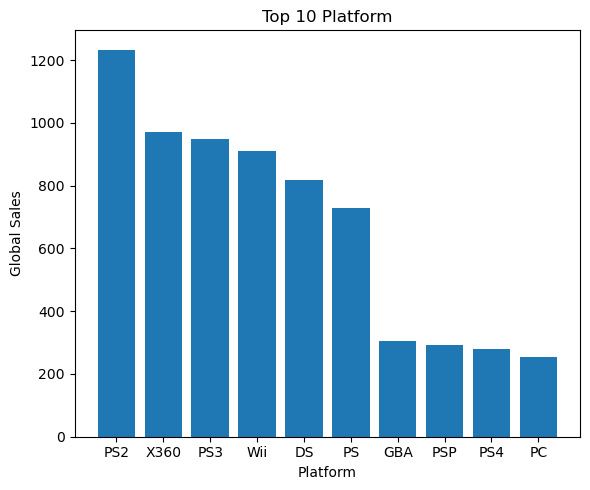

In [120]:
top_platform = by_platform.head(10)

plt.figure(figsize=(6,5))
plt.bar(top_platform['Platform'], top_platform['global_sales'])
plt.title('Top 10 Platform')
plt.xlabel('Platform')
plt.ylabel('Global Sales')
plt.tight_layout()
plt.show()

### Zadanie 23: Line plot – trend roczny sprzedaży
**Cel techniczny:** `plt.plot`.

1) Użyj `by_year` i narysuj trend `Global_Sales` per `Year`.
2) Zadbaj o czytelność osi (figsize).
3) (Opcjonalnie) Zaznacz na wykresie rok z maksymalną sprzedażą.


,Year,global_sales,games,avg_sales
0,1980,11.38,9,1.264444
1,1981,35.77,46,0.777609
2,1982,28.86,36,0.801667


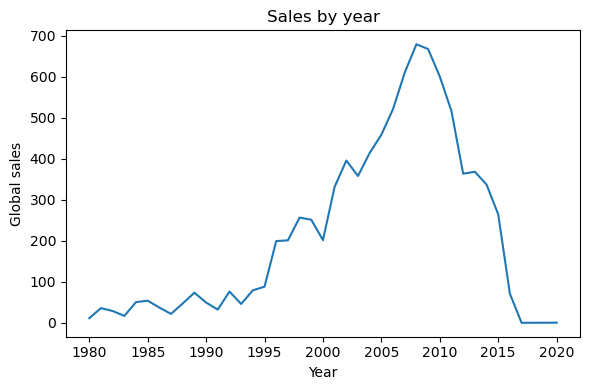

In [129]:
display(by_year.head(3))

plt.figure(figsize=(6,4))
plt.plot(by_year.Year, by_year.global_sales)
plt.title('Sales by year')
plt.xlabel('Year')
plt.ylabel('Global sales')
plt.tight_layout()
plt.show()

# TODO (opcjonalnie): oznaczenie maksimum


### Zadanie 24: Rozkład sprzedaży – histogram i/lub boxplot
**Kontekst:** sprzedaż często ma „długi ogon” (kilka hitów, reszta mało).

1) Zrób histogram `Global_Sales`.
2) (Opcjonalnie) zrób wersję z osią X w skali log (albo z logarytmem sprzedaży `np.log1p`).
3) (Opcjonalnie) boxplot `Global_Sales`.


In [ ]:
# TODO: histogram
# plt.figure(figsize=(8,4))
# plt.hist(df['Global_Sales'], bins=50)
# plt.title('Rozkład Global_Sales')
# plt.xlabel('Global_Sales (mln)')
# plt.ylabel('Liczba gier')
# plt.tight_layout(); plt.show()

# TODO (opcjonalnie): log1p

# TODO (opcjonalnie): boxplot


### Zadanie 25: Storytelling – porównanie preferencji regionów
**Kontekst:** NA/EU/JP mogą mieć inne top gatunki.

1) Na podstawie `genre_region` wybierz top 8 gatunków wg sprzedaży globalnej (suma NA+EU+JP lub użyj Global jeśli wygodniej).
2) Zrób wykres porównawczy: dla każdego gatunku 3 słupki (NA, EU, JP) **albo** 3 osobne wykresy.
3) W markdown: 2–3 zdania wniosków (konkret!).


In [ ]:
# TODO: przygotuj dane do wykresu (top gatunki)
# TODO: wykres porównawczy
# Wskazówka: dla matplotlib łatwo zrobić 3 osobne wykresy (jeden pod drugim) zamiast kombinowania.


# Część F. Łączenie danych (merge) + mini-case (~45–60 min)
W tej części tworzymy małą tabelę mapującą platformy na „rodzinę/brand” (umownie) i łączymy z głównym datasetem.


### Zadanie 26: Stwórz tabelę mapującą (platform → brand_family)
**Kontekst:** w realnej pracy często masz słownik / mapping od biznesu.

1) Zbuduj mały DataFrame `platform_map` z kolumnami: `Platform`, `brand_family`.
2) Wpisz co najmniej 10 popularnych platform (np. Wii, NES, SNES, PS2, PS3, PS4, X360, XB, PC, DS, 3DS) i przypisz rodzinę (np. Nintendo/Sony/Microsoft/PC/Other).
3) Sprawdź, czy w `df` są platformy, których nie ma w mapie (left join pokaże NaN w `brand_family`).


In [ ]:
# TODO: platform_map = pd.DataFrame({
#     'Platform': [...],
#     'brand_family': [...]
# })

# TODO: df_with_brand = df.merge(platform_map, on='Platform', how='left')
# TODO: policz ile NaN w brand_family
# TODO: pokaż przykładowe platformy bez mapowania


### Zadanie 27: Mini-case – sprzedaż per brand_family
**Kontekst:** zamiast 30 platform chcesz raport na 4–5 „rodzin”.

1) Policz sumę sprzedaży globalnej per `brand_family`.
2) Policz udział procentowy w rynku.
3) Zrób wykres słupkowy i napisz 2 zdania wniosków.

Uwaga: jeśli masz dużo braków `brand_family`, zdecyduj co robisz (np. `fillna('Other')`).


In [ ]:
# TODO: dfb = df_with_brand.copy()
# TODO: dfb['brand_family'] = dfb['brand_family'].fillna('Other')

# TODO: by_brand = ...
# TODO: dodaj udział procentowy
# TODO: wykres


# Część G. Mini-projekt: Market snapshot (~30–40 min)
Twoim zadaniem jest zrobić mini-raport jak do Slacka/Confluence: 3 KPI + 2 wykresy + krótkie wnioski.


### Zadanie 28 (mini-projekt): Market snapshot (1 slajd)
**Wymagania:**
- 3 KPI (liczby):
  1) całkowita sprzedaż globalna (suma)
  2) liczba gier
  3) platforma #1 po sprzedaży (nazwa + sprzedaż)
- 2 wykresy (czytelne):
  - top 10 platform po sprzedaży
  - trend roczny sprzedaży
- 5 zdań wniosków maksymalnie (konkrety)

**Tip:** najpierw policz KPI i dopiero potem dobieraj wykresy.


In [ ]:
# TODO: KPI 1) total_global_sales = ...
# TODO: KPI 2) n_games = ...
# TODO: KPI 3) top_platform_name, top_platform_sales = ...

# print('KPI:')
# print('Total Global Sales:', total_global_sales)
# print('Number of games:', n_games)
# print('Top platform:', top_platform_name, top_platform_sales)

# TODO: wykres 1) top platformy
# TODO: wykres 2) trend roczny


# Część H. Polars (intro, ~15–25 min)
Cel: zobaczyć analogiczne operacje jak w pandas i zrozumieć, kiedy polars ma sens.

Jeśli nie masz polars zainstalowanego, możesz pominąć tę część.


### Zadanie 29: Polars – szybkie EDA w kilku linijkach
**Cel techniczny:** `pl.read_csv`, `group_by`, `agg`, `sort`, `head`.

1) Wczytaj CSV do `pl_df`.
2) Policz top 10 platform po sumie `Global_Sales`.
3) Policz sprzedaż per rok (sumy) i pokaż 10 pierwszych wierszy.
4) (Opcjonalnie) Porównaj z pandas: czy wyniki „z grubsza” się zgadzają?


In [ ]:
if not _HAS_POLARS:
    print('Polars nie jest zainstalowany – pomiń tę część lub zainstaluj: pip install polars')
else:
    # TODO: pl_df = pl.read_csv('vgsales_clean.csv')
    # TODO: top_pl = ...
    # TODO: by_year_pl = ...
    # print(top_pl)
    # print(by_year_pl)
    pass


## Bonus (dla szybkich): 5 mikro-zadań (do wyboru)
1) Zrób ranking top 10 gier osobno dla NA i JP (po sprzedaży regionalnej) i porównaj overlap.
2) Dla 2 wybranych lat (np. 2000 i 2010) porównaj top 5 gatunków – czy się zmieniły?
3) Zbuduj tabelę: `Platform` x `Genre` → suma Global_Sales (pivot_table) i znajdź top 5 kombinacji.
4) Sprawdź, czy top platformy różnią się średnią sprzedażą na grę (mean) vs sumą (sum).
5) Zrób prosty wykres zależności NA vs EU (scatter) i skomentuj.
